**KV cache 显存分配**

大模型推理系统倾向于将KV cache 存放到一块连续的内存中，且由于每个请求的输出的序列长度不固定，所以推理系统预先分配了一块连续的内存给每个请求，而不管请求的实际输入和输出token的长度。这就造成了内存的浪费。<br>
KV cache 的大小随着请求量的增加而激增。<br>

举例：对于 13B 的模型，隐藏层维度h=5120，层数 layer=40，假设其生成token的最大数量为2048。<br>
公式： KV Cache显存占用 (字节) = 2 * batch_size * seq_len * kv_dim * num_layers * num_bytes <br>
2 代表同时存储了 K 和 V。<br>
num_bytes 由精度决定（FP16/BF16为2，INT8为1，FP32为4）。<br>
单个token的KV cache 显存占用为：2×1×1×5120×40×2=800K<br>

总KV cache 显存占用为：采用预分配的方式，需要800×2048=1.6G，即使GPU所有显存都用于存储KV cache，也仅仅能够处理几十条的请求。<br>

故，高效管理KV cache，减少内存占用成为推理加速的关键之一！<br>

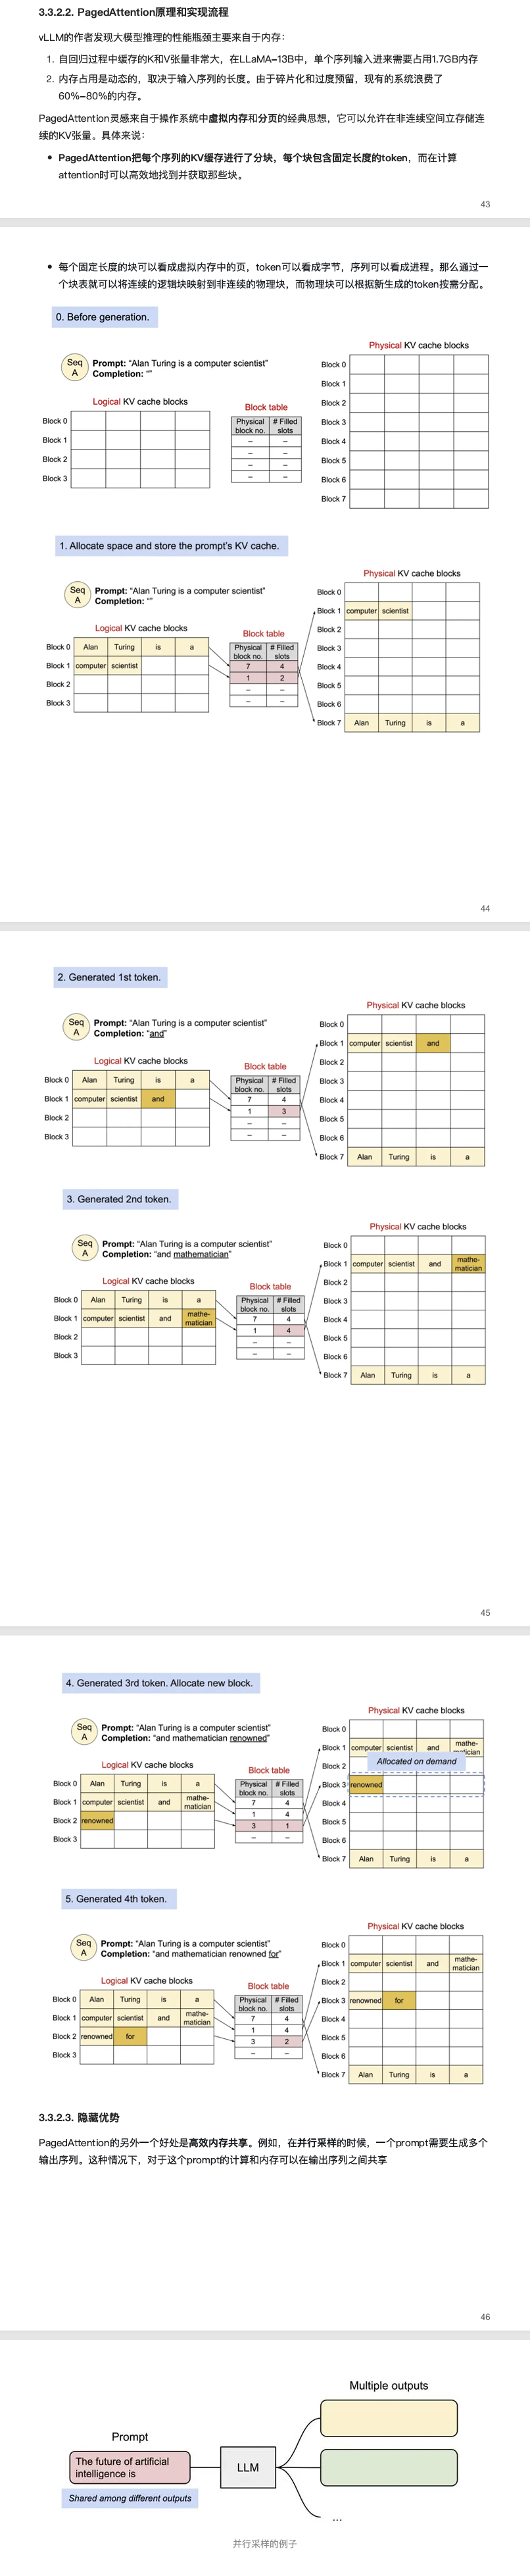

通过pageAttention机制，实现KV cache可以被存放在不连续的GPU显存中。


物理显存（physical VRAM）
指的是真实硬件上的显存容量，比如显卡标称 24GB / 48GB。
这是 GPU 板子上“真的有多少显存”。
逻辑显存（logical / virtual / effective VRAM）
指“从软件视角看起来能用的显存/可承载的显存规模”，不一定等于那块卡上真实的物理显存。





共享的做法是：
prompt 的 KV cache：只存一份，多条输出都指向它
每条输出自己的新增 KV（生成阶段的 token）才各自增长
所以图里就是：一个 Prompt → LLM → 分叉成 Multiple outputs，但它们“共享前缀”，各自只维护自己的后缀部分。